# 11c — Figure 2: subset-balanced audit of 100 existing PySR seeds

Notebook 12 showed that Notebook 11's Figure 2 quadratic fits the many Pantheon+ supernovae better than the six DESI measurements. This **exploratory, post-audit** experiment asks whether one of the already-completed 100 Notebook 10 seed-selected expressions fits both subsets more evenly. Notebook 11 remains the original independent selection; this notebook does not overwrite it. Figure 3 is frozen.

## Fixed protocol for this new experiment

1. Use only the 100 fixed Figure 2, public-covariance, seed-selected PySR expressions from Notebook 10. No new search and no coefficient refit.
2. Preserve Notebook 11's physical checks: finite distance and first/second derivatives and $w(z)$ on $0\le z\le 2.33$, $D_M(0)=0$, positive and increasing distance, positive Eq. (5) denominator factor. Preserve its original combined-loss gate: at most 1.5 times the minimum physically eligible loss.
3. Evaluate each surviving expression against the six DESI points and 1590 Pantheon+ supernovae using the **separate marginal full-covariance blocks**. The nominal prepared covariance has zero DESI–SN cross block.
4. Minimize the worst subset score, $\max(\chi^2_{\rm DESI}/6,\chi^2_{\rm SN}/1590)$. Break exact ties by combined $\chi^2/1596$, then complexity, then seed. This rule is chosen because Notebook 12 exposed a subgroup imbalance; it is **not a preregistered reproduction criterion**.

The subgroup $\chi^2/N$ values are diagnostics, not reduced chi-squared and not a hypothesis test. Six DESI points make the DESI score noisy. The output records every candidate, the rule, source hashes, and a separate timestamped experiment directory.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image
PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / 'results/08_fig23_data_preparation/fig2_pantheon.npz').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from src.fig2_balanced_seed_audit import run_notebook11c
OUTPUT_ROOT = PROJECT_ROOT / 'results/11c_fig2_balanced_seed_audit'
print('Project:', PROJECT_ROOT)

Project: /Users/kemingliu/Desktop/Dark Energy


## Run or inspect

The notebook opens in inspection mode to avoid generating duplicate experiments. Set `RUN_ANALYSIS=True` to make a new folder. The command-line runner does this automatically.

In [2]:
RUN_ANALYSIS = False
if RUN_ANALYSIS:
    EXPERIMENT_DIR, SUMMARY = run_notebook11c(PROJECT_ROOT)
else:
    completed = sorted(p for p in OUTPUT_ROOT.glob('fig2_balanced_*')
                       if (p / 'experiment.json').is_file() and
                       json.loads((p / 'experiment.json').read_text()).get('status') == 'complete')
    if not completed:
        raise FileNotFoundError('No completed 11c run; set RUN_ANALYSIS=True.')
    EXPERIMENT_DIR = completed[-1]
    SUMMARY = json.loads((EXPERIMENT_DIR / 'summary.json').read_text())
print('Experiment:', EXPERIMENT_DIR)
print('Candidate counts:', SUMMARY['candidate_count'], 'total,',
      SUMMARY['eligible_count'], 'physically eligible,',
      SUMMARY['loss_gate_count'], 'inside original loss gate')

Experiment: /Users/kemingliu/Desktop/Dark Energy/results/11c_fig2_balanced_seed_audit/fig2_balanced_20261016T044854959271Z_1a017e27
Candidate counts: 100 total, 29 physically eligible, 26 inside original loss gate


## Compare the original and exploratory choices

These are the raw, fixed PySR expressions. A separately refitted exponential is not a new seed selection. Inspect the DESI/SN score plane and DESI residuals before interpreting either model.

,seed,family,complexity,expression,desi_chi2_per_point,sn_chi2_per_point,combined_chi2_per_point,notebook11_primary,notebook11c_selected
60,20261064,polynomial_degree_2,7,z*(28.99729801609955 - 5.71445618323668*z),6.987947,0.897183,0.92008,True,False
89,20261093,a*z*exp(b*z),9,29.321836856709833*z/1.2843234947453503**z,1.713708,0.880518,0.88365,False,True


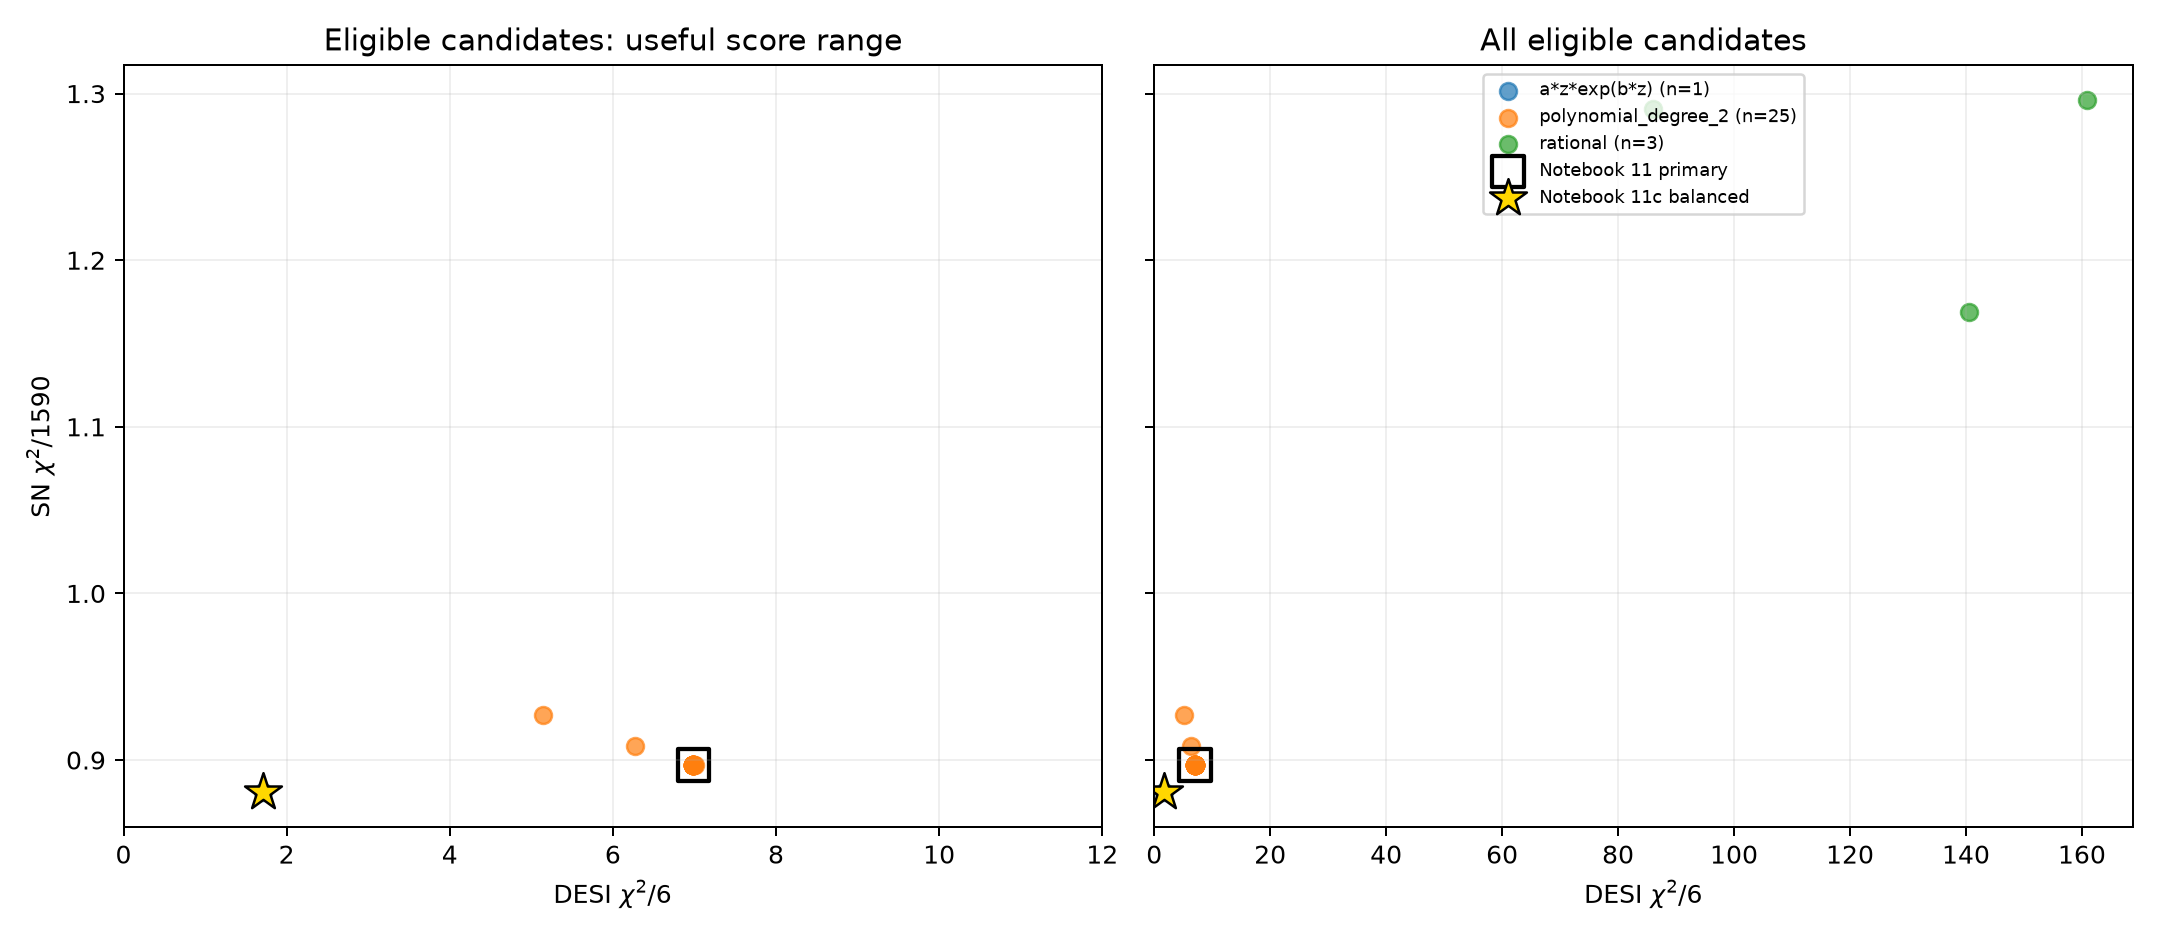

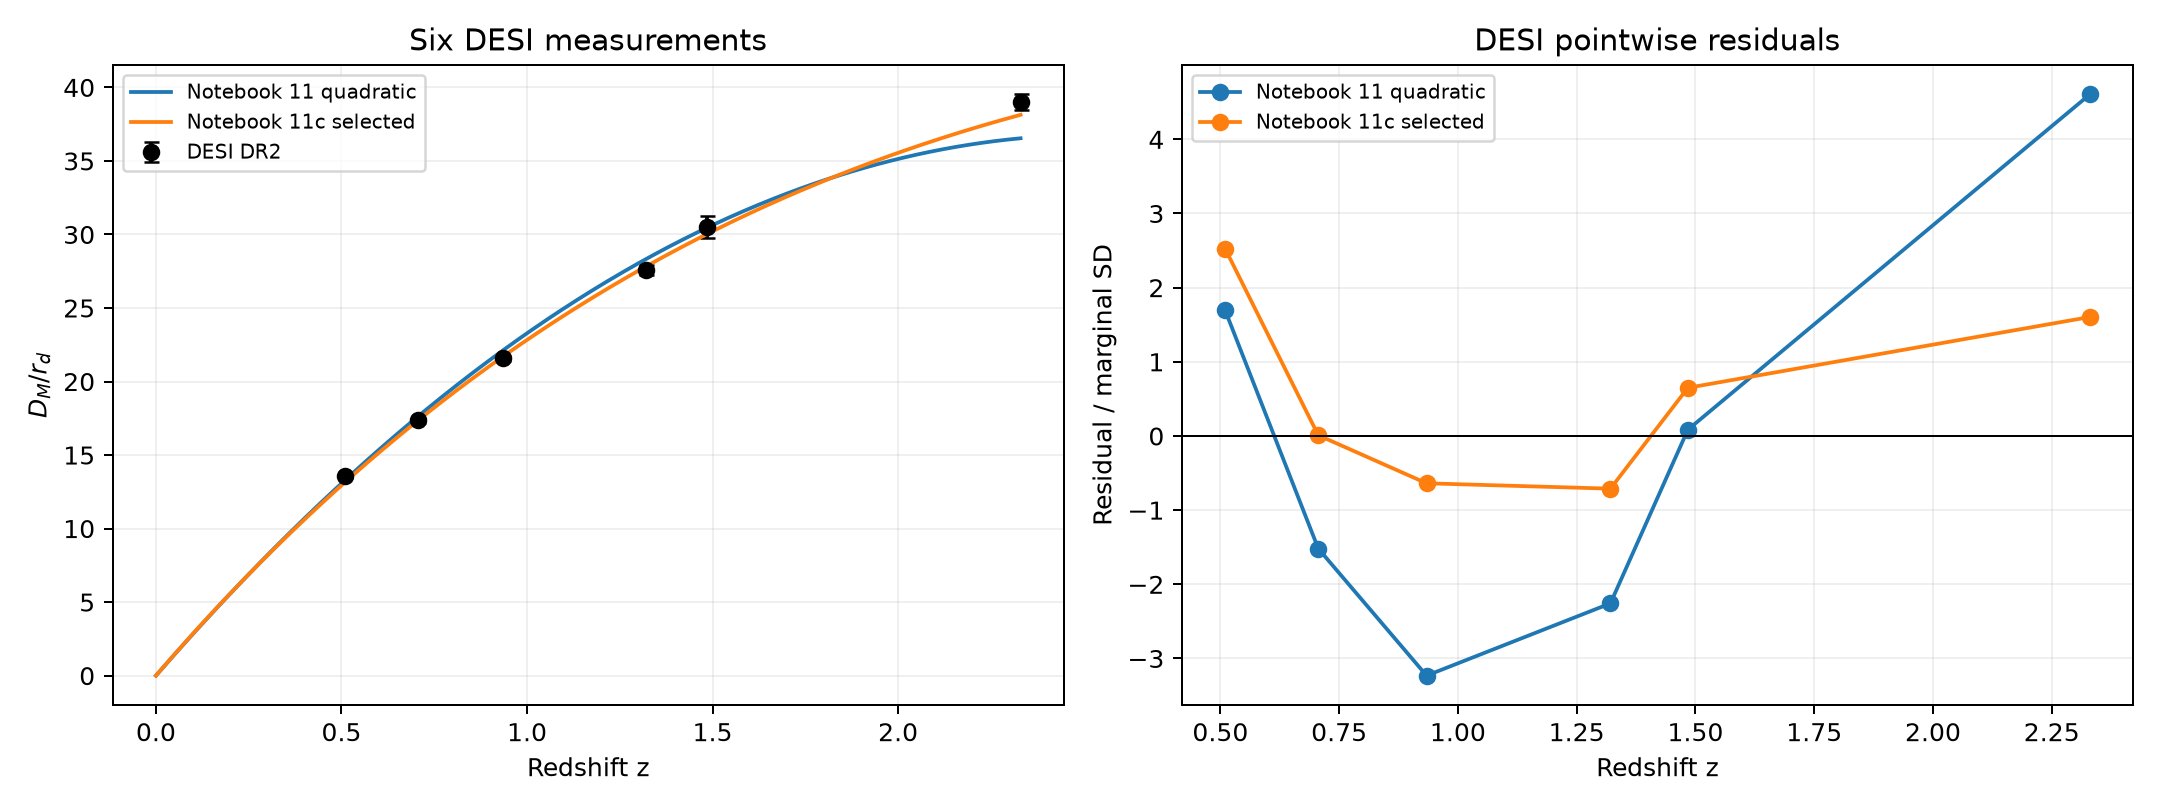

In [3]:
scores = pd.read_csv(EXPERIMENT_DIR / 'candidate_subset_scores.csv')
selected = scores.loc[scores.notebook11_primary | scores.notebook11c_selected]
display(selected[['seed', 'family', 'complexity', 'expression',
                  'desi_chi2_per_point', 'sn_chi2_per_point',
                  'combined_chi2_per_point', 'notebook11_primary',
                  'notebook11c_selected']])
display(Image(filename=str(EXPERIMENT_DIR / 'candidate_subset_scores.png')))
display(Image(filename=str(EXPERIMENT_DIR / 'desi_fit_comparison.png')))

## Interpretation and limits

Read `analysis.md` and `experiment.json` in the run directory for the exact recorded result. This notebook **does not** provide new Monte Carlo bands for the re-selected expression. If the model choice changes, the next experiment should rerun the same uncertainty protocol as Notebook 11/11b for that fixed structure. Do not present this post-audit choice as the original Notebook 11 independent result or select it because its $w(z)$ is closer to the paper or $\Lambda$CDM.